In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
pd.set_option("display.max_columns", None)
sns.set_style("whitegrid")

In [3]:
RAW_PATH="data/raw/roast_and_grind_transactions.csv"
CLEAN_PATH="data/processed/clean_transactions.csv"

In [4]:
df=pd.read_csv(RAW_PATH)
df.head()

,InvoiceNo,CustomerID,InvoiceDate,ProductName,Category,Quantity,UnitPrice,TotalAmount
0,INV_10001,CUST_0001,2026-06-12,Paper Filters (100 pack),Accessories,1,8.5,8.5
1,INV_10001,CUST_0001,2026-06-12,Whole Bean - Single Origin (250g),Coffee Beans,2,22.0,44.0
2,INV_10002,CUST_0001,2026-08-30,Whole Bean - Single Origin (250g),Coffee Beans,1,22.0,22.0
3,INV_10003,CUST_0002,2025-12-19,Whole Bean - Single Origin (250g),Coffee Beans,1,22.0,22.0
4,INV_10003,CUST_0002,2025-12-19,Whole Bean - Espresso Roast (1kg),Coffee Beans,1,54.0,54.0


In [5]:
#Last 5 Rows
df.tail()

,InvoiceNo,CustomerID,InvoiceDate,ProductName,Category,Quantity,UnitPrice,TotalAmount
8159,INV_16039,CUST_1200,2026-07-13,Pour-Over Dripper (Ceramic),Brew Gear,1,28.0,28.0
8160,INV_16040,CUST_1200,2026-08-01,Whole Bean - House Blend (250g),Coffee Beans,1,16.5,16.5
8161,INV_16041,CUST_1200,2026-08-09,Burr Hand Grinder,Brew Gear,1,68.0,68.0
8162,INV_16042,CUST_1200,2026-11-08,Burr Hand Grinder,Brew Gear,1,68.0,68.0
8163,INV_16042,CUST_1200,2026-11-08,Pour-Over Dripper (Ceramic),Brew Gear,1,28.0,28.0


In [6]:
#Information of the database
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8164 entries, 0 to 8163
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   InvoiceNo    8164 non-null   str    
 1   CustomerID   8164 non-null   str    
 2   InvoiceDate  8164 non-null   str    
 3   ProductName  8164 non-null   str    
 4   Category     8164 non-null   str    
 5   Quantity     8164 non-null   int64  
 6   UnitPrice    8164 non-null   float64
 7   TotalAmount  8164 non-null   float64
dtypes: float64(2), int64(1), str(5)
memory usage: 1.0 MB


In [7]:
#Statistical information about the database
df.describe()

,Quantity,UnitPrice,TotalAmount
count,8164.000000,8164.000000,8164.000000
mean,1.122734,30.846399,34.117528
std,0.563392,20.961219,27.998082
min,-3.000000,8.500000,-162.000000
25%,1.000000,16.500000,16.500000
50%,1.000000,22.000000,22.000000
75%,1.000000,54.000000,54.000000
max,3.000000,85.000000,162.000000


In [8]:
#Shape of the data
df.shape

(8164, 8)

In [9]:
#Check for missing values
print("Missing Values:","\n",df.isnull().sum())

#check for duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

Missing Values: 
 InvoiceNo      0
CustomerID     0
InvoiceDate    0
ProductName    0
Category       0
Quantity       0
UnitPrice      0
TotalAmount    0
dtype: int64

Duplicate rows: 0


In [10]:
print("\nDate range:")
print(df["InvoiceDate"].min(), "to", df["InvoiceDate"].max())

print("\nProduct categories:")
print(df["Category"].value_counts())


Date range:
2025-11-16 to 2026-11-15

Product categories:
Category
Coffee Beans    5349
Brew Gear       1701
Accessories     1114
Name: count, dtype: int64


In [11]:
# Convert date column
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")

# Remove exact duplicates
df = df.drop_duplicates()

# Remove rows with missing essential identifiers
df = df.dropna(subset=["InvoiceNo", "CustomerID", "InvoiceDate"])

# Remove invalid prices
df = df[df["UnitPrice"] > 0]

# Separate returns from completed purchases
returns = df[df["Quantity"] < 0].copy()
purchases = df[df["Quantity"] > 0].copy()

print("Completed purchase rows:", purchases.shape[0])
print("Return rows:", returns.shape[0])

Completed purchase rows: 8005
Return rows: 159


In [12]:
# Recalculate transaction value for consistency
purchases["TotalAmount"] = purchases["Quantity"] * purchases["UnitPrice"]

# Create useful time features
purchases["InvoiceYear"] = purchases["InvoiceDate"].dt.year
purchases["InvoiceMonth"] = purchases["InvoiceDate"].dt.to_period("M")
purchases["InvoiceWeekday"] = purchases["InvoiceDate"].dt.day_name()

purchases.head()

,InvoiceNo,CustomerID,InvoiceDate,ProductName,Category,Quantity,UnitPrice,TotalAmount,InvoiceYear,InvoiceMonth,InvoiceWeekday
0,INV_10001,CUST_0001,2026-06-12,Paper Filters (100 pack),Accessories,1,8.5,8.5,2026,2026-06,Friday
1,INV_10001,CUST_0001,2026-06-12,Whole Bean - Single Origin (250g),Coffee Beans,2,22.0,44.0,2026,2026-06,Friday
2,INV_10002,CUST_0001,2026-08-30,Whole Bean - Single Origin (250g),Coffee Beans,1,22.0,22.0,2026,2026-08,Sunday
3,INV_10003,CUST_0002,2025-12-19,Whole Bean - Single Origin (250g),Coffee Beans,1,22.0,22.0,2025,2025-12,Friday
4,INV_10003,CUST_0002,2025-12-19,Whole Bean - Espresso Roast (1kg),Coffee Beans,1,54.0,54.0,2025,2025-12,Friday


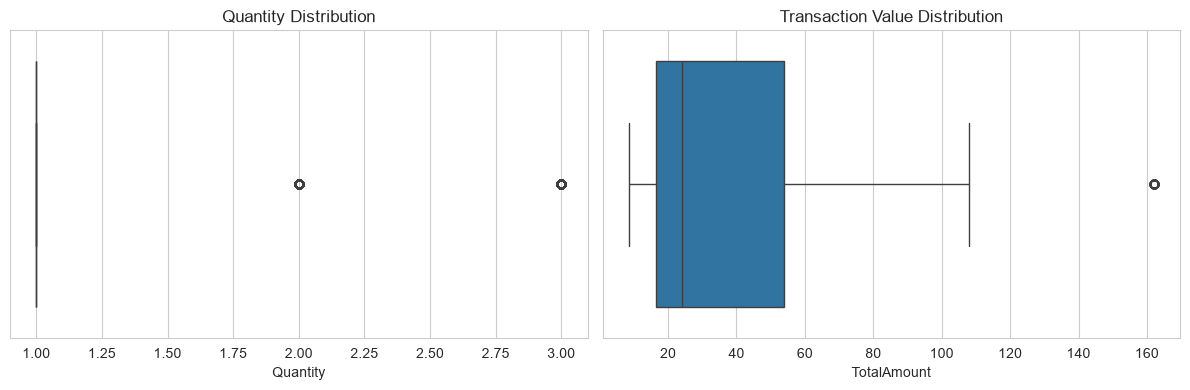

In [13]:
# Outlier inspection
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
sns.boxplot(x=purchases["Quantity"])
plt.title("Quantity Distribution")

plt.subplot(1, 2, 2)
sns.boxplot(x=purchases["TotalAmount"])
plt.title("Transaction Value Distribution")

plt.tight_layout()
plt.savefig("Outputs/Figures/outlier_check.png", bbox_inches="tight")
plt.show()

In [14]:
# Keep extreme but valid purchases; do not blindly remove high-value customers
# Remove only impossible values
purchases = purchases[
    (purchases["Quantity"] <= purchases["Quantity"].quantile(0.999)) &
    (purchases["TotalAmount"] <= purchases["TotalAmount"].quantile(0.999))
]

purchases.to_csv(CLEAN_PATH, index=False)

print("Cleaned dataset saved:",CLEAN_PATH)
print("Final cleaned shape:", purchases.shape)

Cleaned dataset saved: data/processed/clean_transactions.csv
Final cleaned shape: (8005, 11)
